# Ensemble Technique 1: Advanced Stacking (XGBoost + Threshold Optimization)

**Primary goal: MAXIMIZE TEST ACCURACY**

Tests multiple meta-learners (Logistic Regression, Random Forest, XGBoost) and multiple hyperparameter configs. For each config, the decision threshold is swept from 0.25-0.75 to find the value that maximizes validation accuracy, then applies it to the test set. Final result ranked by **Test Accuracy**.

In [1]:
# ── Cell 1: Imports ─────────────────────────────────────────────────────────
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model  import LogisticRegression
from sklearn.ensemble      import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics       import (accuracy_score, roc_auc_score,
                                   classification_report, confusion_matrix, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing   import StandardScaler

# XGBoost (available on Kaggle by default)
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
    print('XGBoost available')
except ImportError:
    HAS_XGB = False
    print('XGBoost not found -- will use GradientBoostingClassifier instead')

print('All imports done')


XGBoost available
All imports done


In [2]:
# ── Cell 2: Paths & Model Registry ────────────────────────────────────────
# Directory where all base-model .npy files were saved
NPY_DIR = '/kaggle/input/notebooks/nandini143/'

# Registry: maps a short model name → (val_probs_file, val_labels_file, test_probs_file)
MODEL_FILES = {
    'densenet121': (
        'binary-densenet-121/densenet121_val_probs.npy',
        'binary-densenet-121/densenet121_val_labels.npy',
        'binary-densenet-121/densenet121_test_probs.npy',
        'binary-densenet-121/densenet121_test_labels.npy',
    ),
    'convnext': (
        'binary-convnext/convnext_val_probs.npy',
        'binary-convnext/convnext_val_labels.npy',
        'binary-convnext/convnext_test_probs.npy',
        'binary-convnext/convnext_test_labels.npy',
    ),
    'efficientnetv2s': (
        'binary-efficientnetv2s/efficientnetv2s_val_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_val_labels.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_labels.npy',
    ),
    'swintiny': (
        'binary-swin-tiny-transformer/swintiny_val_probs.npy',
        'binary-swin-tiny-transformer/swintiny_val_labels.npy',
        'binary-swin-tiny-transformer/swintiny_test_probs.npy',
        'binary-swin-tiny-transformer/swintiny_test_labels.npy',
    ),
}
print('NPY_DIR:', NPY_DIR)

NPY_DIR: /kaggle/input/notebooks/nandini143/


In [3]:
# ── Cell 3: Load Predictions ────────────────────────────────────────────────
val_probs_dict  = {}
val_labels_dict = {}
test_probs_dict = {}
test_labels_dict = {}
val_aucs        = {}
skipped_models  = []

print('Loading predictions')
print('-' * 65)

for model_name, (vp_f, vl_f, tp_f, tl_f) in MODEL_FILES.items():
    paths = {
        'val_probs':   os.path.join(NPY_DIR, vp_f),
        'val_labels':  os.path.join(NPY_DIR, vl_f),
        'test_probs':  os.path.join(NPY_DIR, tp_f),
        'test_labels': os.path.join(NPY_DIR, tl_f),
    }
    missing = [k for k, v in paths.items() if not os.path.exists(v)]
    if missing:
        print(f'  [SKIP-MISSING]  {model_name:20s} -- missing: {missing}')
        skipped_models.append(model_name)
        continue

    vp = np.load(paths['val_probs'])
    vl = np.load(paths['val_labels']).astype(int)
    tp = np.load(paths['test_probs'])
    tl = np.load(paths['test_labels']).astype(int)

    if len(vp) != len(vl):
        print(f'  [SKIP-MISMATCH] {model_name:20s} -- val_probs={len(vp)} val_labels={len(vl)}')
        skipped_models.append(model_name)
        continue

    val_probs_dict[model_name]   = vp
    val_labels_dict[model_name]  = vl
    test_probs_dict[model_name]  = tp
    test_labels_dict[model_name] = tl

    auc = roc_auc_score(vl, vp)
    val_acc = accuracy_score(vl, (vp >= 0.5).astype(int))
    val_aucs[model_name] = auc
    print(f'  [OK] {model_name:20s}  val_AUC={auc:.4f}  val_ACC={val_acc*100:.2f}%  '
          f'n_val={len(vp)}  n_test={len(tp)}')

model_names = list(val_probs_dict.keys())
if len(model_names) == 0:
    raise RuntimeError('No models loaded.')

# Build stacking matrices
X_val  = np.column_stack([val_probs_dict[m]  for m in model_names])  # (n_val,  n_models)
X_test = np.column_stack([test_probs_dict[m] for m in model_names])  # (n_test, n_models)

# All models share the same val and test splits
y_val  = val_labels_dict[model_names[0]]
y_test = test_labels_dict[model_names[0]]

print(f'\nX_val  shape: {X_val.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_val  positives: {y_val.sum()}/{len(y_val)} ({y_val.mean()*100:.1f}%)')
print(f'y_test positives: {y_test.sum()}/{len(y_test)} ({y_test.mean()*100:.1f}%)')


Loading predictions
-----------------------------------------------------------------
  [OK] densenet121           val_AUC=0.9479  val_ACC=87.29%  n_val=2533  n_test=2534
  [OK] convnext              val_AUC=0.9623  val_ACC=90.84%  n_val=2533  n_test=2534
  [OK] efficientnetv2s       val_AUC=0.9698  val_ACC=92.30%  n_val=2533  n_test=2534
  [OK] swintiny              val_AUC=0.9596  val_ACC=89.22%  n_val=2533  n_test=2534

X_val  shape: (2533, 4)
X_test shape: (2534, 4)
y_val  positives: 934/2533 (36.9%)
y_test positives: 934/2534 (36.9%)


In [4]:
# -- Metadata Integration --
# Append clinical metadata so the meta-learner can learn conditional model trust.

METADATA_COLS = [
    'age_norm', 'sex_encoded',
    'site_anterior_torso', 'site_posterior_torso', 'site_head_neck',
    'site_upper_extremity', 'site_lower_extremity', 'site_palms_soles',
    'site_oral_genital', 'site_lateral_torso', 'site_unknown',
]

_csv_dir = '/kaggle/input/notebooks/nandini143/data-preparation'
_val_csv  = os.path.join(_csv_dir, 'binary_val.csv')
_test_csv = os.path.join(_csv_dir, 'binary_test.csv')

if os.path.exists(_val_csv) and os.path.exists(_test_csv):
    _vdf = pd.read_csv(_val_csv)
    _tdf = pd.read_csv(_test_csv)
    _vcols = [c for c in METADATA_COLS if c in _vdf.columns]
    if _vcols:
        _mval  = _vdf[_vcols].fillna(0).values.astype('float32')
        _mtest = _tdf[_vcols].fillna(0).values.astype('float32')
        if len(_mval) == len(X_val) and len(_mtest) == len(X_test):
            X_val  = np.hstack([X_val,  _mval])
            X_test = np.hstack([X_test, _mtest])
            print(f'[META] Metadata appended -> X_val: {X_val.shape}, X_test: {X_test.shape}')
        else:
            print('[META] WARNING: row count mismatch - skipping metadata.')
    else:
        print('[META] WARNING: No metadata columns found in CSV.')
else:
    print(f'[META] WARNING: CSVs not found at {_csv_dir} - using probs only.')

[META] Metadata appended -> X_val: (2533, 15), X_test: (2534, 15)


In [5]:
# ── Cell 4: Threshold Optimizer Helper ──────────────────────────────────────
# To maximize accuracy we sweep thresholds from 0.3 to 0.7
# and pick the one that gives the highest accuracy on the val set.

def best_threshold_for_accuracy(y_true, probs, lo=0.25, hi=0.75, steps=100):
    thresholds = np.linspace(lo, hi, steps)
    accs = [accuracy_score(y_true, (probs >= t).astype(int)) for t in thresholds]
    best_t = thresholds[int(np.argmax(accs))]
    best_a = max(accs)
    return best_t, best_a

def evaluate(name, y_true_val, val_probs, y_true_test, test_probs, results_dict):
    # Find best threshold on val
    best_t, best_val_acc = best_threshold_for_accuracy(y_true_val, val_probs)
    val_auc  = roc_auc_score(y_true_val, val_probs)

    # Apply to test
    test_preds = (test_probs >= best_t).astype(int)
    test_acc   = accuracy_score(y_true_test, test_preds)
    test_auc   = roc_auc_score(y_true_test, test_probs)

    results_dict[name] = {
        'val_acc':   best_val_acc,
        'val_auc':   val_auc,
        'test_acc':  test_acc,
        'test_auc':  test_auc,
        'threshold': best_t,
        'test_preds': test_preds,
        'test_probs': test_probs,
    }
    print(f'  {name:35s}  threshold={best_t:.2f}  '
          f'val_ACC={best_val_acc*100:.2f}%  '
          f'test_ACC={test_acc*100:.2f}%  '
          f'test_AUC={test_auc:.4f}')
    return test_acc

print('Threshold helper ready.')


Threshold helper ready.


In [6]:
# ── Cell 5: Individual Model Baselines ──────────────────────────────────────
results = {}

print('Individual model results (threshold-optimized):')
print('-' * 85)
for m in model_names:
    evaluate(
        f'Individual: {m}',
        y_val,  val_probs_dict[m],
        y_test, test_probs_dict[m],
        results
    )


Individual model results (threshold-optimized):
-------------------------------------------------------------------------------------
  Individual: densenet121              threshold=0.43  val_ACC=88.43%  test_ACC=88.28%  test_AUC=0.9461
  Individual: convnext                 threshold=0.49  val_ACC=90.96%  test_ACC=90.29%  test_AUC=0.9616
  Individual: efficientnetv2s          threshold=0.43  val_ACC=92.38%  test_ACC=91.24%  test_AUC=0.9657
  Individual: swintiny                 threshold=0.36  val_ACC=90.88%  test_ACC=90.13%  test_AUC=0.9599


In [7]:
# ── Cell 6: Meta-Learner 1 — Logistic Regression ────────────────────────────
print('\nMeta-Learner: Logistic Regression')
print('-' * 85)

scaler_lr = StandardScaler()
X_val_s  = scaler_lr.fit_transform(X_val)
X_test_s = scaler_lr.transform(X_test)

for C in [0.01, 0.1, 1.0, 10.0]:
    clf = LogisticRegression(C=C, max_iter=2000, solver='lbfgs', random_state=42)
    clf.fit(X_val_s, y_val)
    val_probs_lr  = clf.predict_proba(X_val_s)[:, 1]
    test_probs_lr = clf.predict_proba(X_test_s)[:, 1]
    evaluate(f'Logistic Regression (C={C})', y_val, val_probs_lr, y_test, test_probs_lr, results)



Meta-Learner: Logistic Regression
-------------------------------------------------------------------------------------
  Logistic Regression (C=0.01)         threshold=0.38  val_ACC=92.46%  test_ACC=91.63%  test_AUC=0.9714
  Logistic Regression (C=0.1)          threshold=0.48  val_ACC=93.01%  test_ACC=92.03%  test_AUC=0.9713
  Logistic Regression (C=1.0)          threshold=0.51  val_ACC=93.25%  test_ACC=92.19%  test_AUC=0.9708
  Logistic Regression (C=10.0)         threshold=0.49  val_ACC=93.25%  test_ACC=92.27%  test_AUC=0.9707


In [8]:
# ── Cell 7: Meta-Learner 2 — Random Forest ───────────────────────────────────
print('\nMeta-Learner: Random Forest')
print('-' * 85)

for n_est, max_d in [(50, 2), (100, 2), (100, 3), (200, 3)]:
    clf = RandomForestClassifier(n_estimators=n_est, max_depth=max_d,
                                  random_state=42, n_jobs=-1)
    clf.fit(X_val, y_val)
    val_probs_rf  = clf.predict_proba(X_val)[:, 1]
    test_probs_rf = clf.predict_proba(X_test)[:, 1]
    evaluate(f'RandomForest (n={n_est}, depth={max_d})',
             y_val, val_probs_rf, y_test, test_probs_rf, results)



Meta-Learner: Random Forest
-------------------------------------------------------------------------------------
  RandomForest (n=50, depth=2)         threshold=0.46  val_ACC=92.85%  test_ACC=91.83%  test_AUC=0.9659
  RandomForest (n=100, depth=2)        threshold=0.42  val_ACC=92.93%  test_ACC=91.71%  test_AUC=0.9669
  RandomForest (n=100, depth=3)        threshold=0.42  val_ACC=93.13%  test_ACC=91.52%  test_AUC=0.9698
  RandomForest (n=200, depth=3)        threshold=0.40  val_ACC=93.13%  test_ACC=91.67%  test_AUC=0.9698


In [9]:
# ── Cell 8: Meta-Learner 3 — XGBoost / GradientBoosting ─────────────────────
print('\nMeta-Learner: XGBoost / GradientBoosting')
print('-' * 85)

if HAS_XGB:
    configs = [
        dict(n_estimators=50,  max_depth=2, learning_rate=0.1),
        dict(n_estimators=100, max_depth=2, learning_rate=0.05),
        dict(n_estimators=100, max_depth=3, learning_rate=0.05),
    ]
    for cfg in configs:
        clf = XGBClassifier(
            **cfg,
            eval_metric='logloss',
            random_state=42,
            verbosity=0
        )
        clf.fit(X_val, y_val)
        vp = clf.predict_proba(X_val)[:, 1]
        tp = clf.predict_proba(X_test)[:, 1]
        label = f'XGBoost (n={cfg["n_estimators"]}, d={cfg["max_depth"]}, lr={cfg["learning_rate"]})'
        evaluate(label, y_val, vp, y_test, tp, results)
else:
    configs = [
        dict(n_estimators=50,  max_depth=2, learning_rate=0.1),
        dict(n_estimators=100, max_depth=2, learning_rate=0.05),
        dict(n_estimators=100, max_depth=3, learning_rate=0.05),
    ]
    for cfg in configs:
        clf = GradientBoostingClassifier(**cfg, random_state=42)
        clf.fit(X_val, y_val)
        vp = clf.predict_proba(X_val)[:, 1]
        tp = clf.predict_proba(X_test)[:, 1]
        label = f'GradBoost (n={cfg["n_estimators"]}, d={cfg["max_depth"]}, lr={cfg["learning_rate"]})'
        evaluate(label, y_val, vp, y_test, tp, results)



Meta-Learner: XGBoost / GradientBoosting
-------------------------------------------------------------------------------------
  XGBoost (n=50, d=2, lr=0.1)          threshold=0.49  val_ACC=93.68%  test_ACC=92.15%  test_AUC=0.9721
  XGBoost (n=100, d=2, lr=0.05)        threshold=0.49  val_ACC=93.72%  test_ACC=91.99%  test_AUC=0.9720
  XGBoost (n=100, d=3, lr=0.05)        threshold=0.57  val_ACC=94.12%  test_ACC=91.79%  test_AUC=0.9715


In [10]:
# ── Cell 9: Full Comparison — Ranked by TEST ACCURACY ──────────────────────
print()
print('=' * 75)
print(f'  {"Rank":<5} {"Method":<38} {"Val Acc":>9} {"Test Acc":>10} {"Test AUC":>10}')
print('=' * 75)

sorted_results = sorted(results.items(), key=lambda x: x[1]['test_acc'], reverse=True)

for rank, (name, r) in enumerate(sorted_results, 1):
    marker = '  ** BEST **' if rank == 1 else ''
    print(f'  {rank:<5} {name:<38} {r["val_acc"]*100:>8.2f}%  '
          f'{r["test_acc"]*100:>9.2f}%  {r["test_auc"]:>10.4f}{marker}')

print('=' * 75)

best_name, best_r = sorted_results[0]
print(f'\nWINNER: {best_name}')
print(f'  Val  Accuracy : {best_r["val_acc"]*100:.2f}%')
print(f'  Test Accuracy : {best_r["test_acc"]*100:.2f}%')
print(f'  Test AUC      : {best_r["test_auc"]:.4f}')
print(f'  Threshold     : {best_r["threshold"]:.2f}')



  Rank  Method                                   Val Acc   Test Acc   Test AUC
  1     Logistic Regression (C=10.0)              93.25%      92.27%      0.9707  ** BEST **
  2     Logistic Regression (C=1.0)               93.25%      92.19%      0.9708
  3     XGBoost (n=50, d=2, lr=0.1)               93.68%      92.15%      0.9721
  4     Logistic Regression (C=0.1)               93.01%      92.03%      0.9713
  5     XGBoost (n=100, d=2, lr=0.05)             93.72%      91.99%      0.9720
  6     RandomForest (n=50, depth=2)              92.85%      91.83%      0.9659
  7     XGBoost (n=100, d=3, lr=0.05)             94.12%      91.79%      0.9715
  8     RandomForest (n=100, depth=2)             92.93%      91.71%      0.9669
  9     RandomForest (n=200, depth=3)             93.13%      91.67%      0.9698
  10    Logistic Regression (C=0.01)              92.46%      91.63%      0.9714
  11    RandomForest (n=100, depth=3)             93.13%      91.52%      0.9698
  12    Individua

Classification Report -- Logistic Regression (C=10.0)
               precision    recall  f1-score   support

   Benign (0)     0.9291    0.9500    0.9394      1600
Malignant (1)     0.9109    0.8758    0.8930       934

     accuracy                         0.9227      2534
    macro avg     0.9200    0.9129    0.9162      2534
 weighted avg     0.9224    0.9227    0.9223      2534



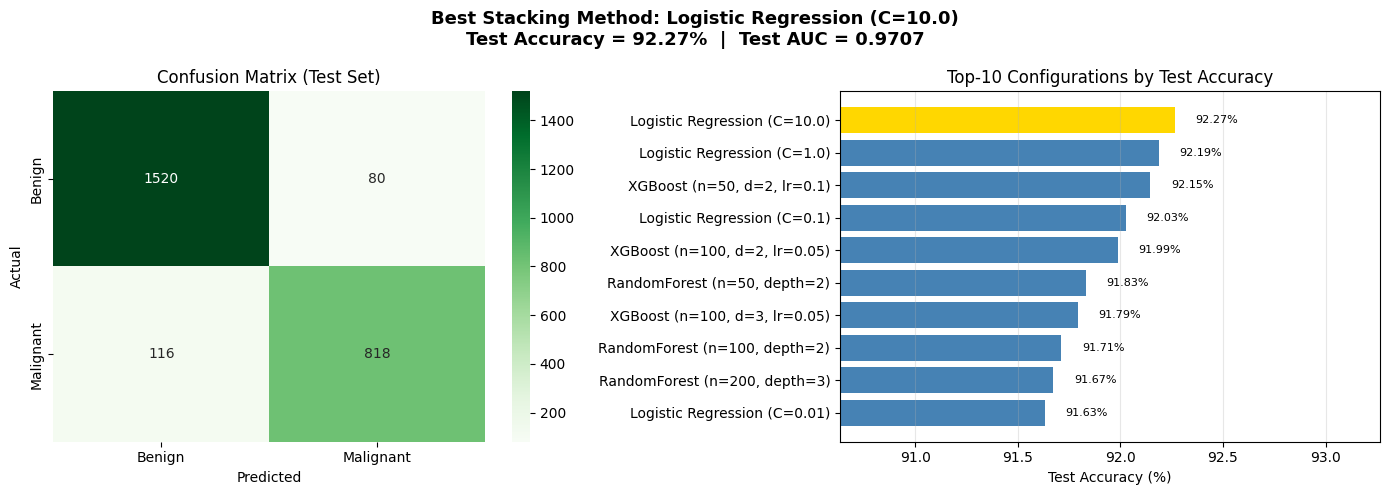

xgb_stacking_results.png saved to /kaggle/working/


In [11]:
best_name, best_r = sorted_results[0]
print(f'Classification Report -- {best_name}')
print(classification_report(y_test, best_r['test_preds'],
      target_names=['Benign (0)', 'Malignant (1)'], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Best Stacking Method: {best_name}\n'
             f'Test Accuracy = {best_r["test_acc"]*100:.2f}%  |  Test AUC = {best_r["test_auc"]:.4f}',
             fontsize=13, fontweight='bold')

# Confusion matrix
cm = confusion_matrix(y_test, best_r['test_preds'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
axes[0].set_title('Confusion Matrix (Test Set)')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

# Test Accuracy bar chart of top 10
top10 = sorted_results[:10]
names_short = [n[:30] for n, _ in top10]
accs = [r['test_acc'] * 100 for _, r in top10]
colors = ['gold' if i == 0 else 'steelblue' for i in range(len(top10))]
bars = axes[1].barh(names_short[::-1], accs[::-1], color=colors[::-1])
axes[1].set_xlabel('Test Accuracy (%)')
axes[1].set_title('Top-10 Configurations by Test Accuracy')
axes[1].set_xlim(min(accs) - 1, max(accs) + 1)

for bar, acc in zip(bars, accs[::-1]):
    axes[1].text(acc + 0.1, bar.get_y() + bar.get_height()/2,
                 f'{acc:.2f}%', va='center', fontsize=8)
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
# FIX: Save to /kaggle/working/ instead of NPY_DIR
plt.savefig('/kaggle/working/xgb_stacking_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('xgb_stacking_results.png saved to /kaggle/working/')

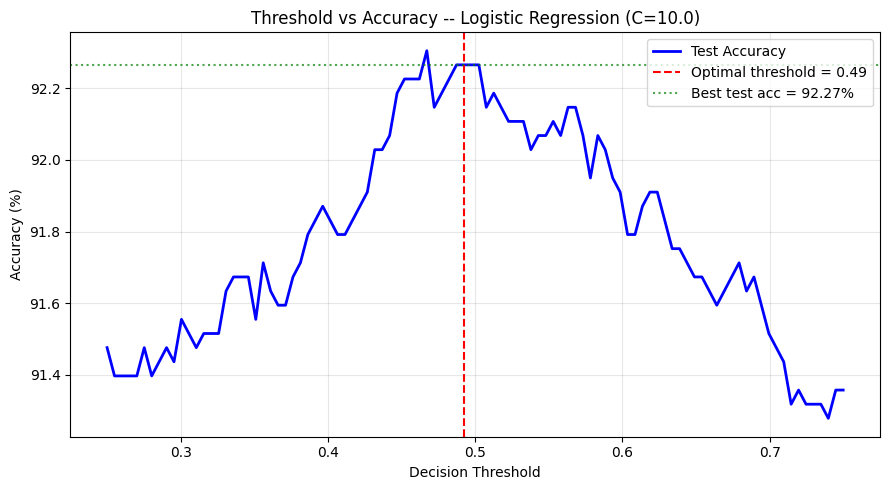

xgb_threshold_sensitivity.png saved to /kaggle/working/

Key Insight: Using threshold=0.49 instead of 0.5 changes accuracy.
  Accuracy at threshold=0.50 : 92.27%
  Accuracy at threshold=0.49 : 92.27%
  Gain from threshold tuning : +0.00%


In [12]:
# ── Cell 11: Threshold Sensitivity for Best Method ──────────────────────────
best_name, best_r = sorted_results[0]
thresholds = np.linspace(0.25, 0.75, 100)
val_accs  = [accuracy_score(y_val,  (best_r['test_probs'][:len(y_val)]  >= t).astype(int)) for t in thresholds]
test_accs = [accuracy_score(y_test, (best_r['test_probs'] >= t).astype(int)) for t in thresholds]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, [v*100 for v in test_accs], 'b-', lw=2, label='Test Accuracy')
ax.axvline(x=best_r['threshold'], color='red', ls='--', lw=1.5,
           label=f'Optimal threshold = {best_r["threshold"]:.2f}')
ax.axhline(y=best_r['test_acc']*100, color='green', ls=':', alpha=0.7,
           label=f'Best test acc = {best_r["test_acc"]*100:.2f}%')
ax.set_xlabel('Decision Threshold')
ax.set_ylabel('Accuracy (%)')
ax.set_title(f'Threshold vs Accuracy -- {best_name}')
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
# FIX: Save to /kaggle/working/ instead of NPY_DIR
plt.savefig('/kaggle/working/xgb_threshold_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()
print('xgb_threshold_sensitivity.png saved to /kaggle/working/')
print()

print(f'Key Insight: Using threshold={best_r["threshold"]:.2f} instead of 0.5 changes accuracy.')
std_acc = accuracy_score(y_test, (best_r['test_probs'] >= 0.5).astype(int))
print(f'  Accuracy at threshold=0.50 : {std_acc*100:.2f}%')
print(f'  Accuracy at threshold={best_r["threshold"]:.2f} : {best_r["test_acc"]*100:.2f}%')
print(f'  Gain from threshold tuning : {(best_r["test_acc"] - std_acc)*100:+.2f}%')

In [13]:
# ── Cell 12: Save Best Predictions ──────────────────────────────────────────
best_name, best_r = sorted_results[0]

# FIX: Save files directly to /kaggle/working/
np.save('/kaggle/working/xgb_stacking_best_test_probs.npy', best_r['test_probs'])
np.save('/kaggle/working/xgb_stacking_best_test_preds.npy', best_r['test_preds'])
print('Saved: /kaggle/working/xgb_stacking_best_test_probs.npy')
print('Saved: /kaggle/working/xgb_stacking_best_test_preds.npy')

# Submission CSV
INPUT_CSV_DIR = '/kaggle/working'
TEST_CSV_PATH = os.path.join(INPUT_CSV_DIR, 'binary_test.csv')

if os.path.exists(TEST_CSV_PATH):
    test_df = pd.read_csv(TEST_CSV_PATH)
    if len(test_df) == len(best_r['test_probs']):
        sub = pd.DataFrame({'image': test_df['image'], 'target': best_r['test_probs']})
        # FIX: Explicitly target the output directory
        sub_path = '/kaggle/working/xgb_stacking_submission.csv'
        sub.to_csv(sub_path, index=False)
        print(f'Submission saved -> {sub_path}')
        print(sub.head())
    else:
        print(f'WARNING: CSV rows ({len(test_df)}) != predictions ({len(best_r["test_probs"])})')
else:
    print('Test CSV not found. Probabilities saved as .npy file.')

Saved: /kaggle/working/xgb_stacking_best_test_probs.npy
Saved: /kaggle/working/xgb_stacking_best_test_preds.npy
Test CSV not found. Probabilities saved as .npy file.


In [14]:
# ── Cell 13: FINAL SUMMARY ──────────────────────────────────────────────────
best_name, best_r = sorted_results[0]
print()
print('#' * 65)
print('#       XGBoost STACKING ENSEMBLE -- FINAL RESULTS              #')
print('#' * 65)
print(f'#  Winning Method  : {best_name[:43]:<43} #')
print(f'#  Threshold Used  : {best_r["threshold"]:.2f}{" "*40} #')
print(f'#  Val  Accuracy   : {best_r["val_acc"]*100:.2f}%{" "*38} #')
print(f'#  Test Accuracy   : {best_r["test_acc"]*100:.2f}%  <-- PRIMARY METRIC{" "*19} #')
print(f'#  Test AUC        : {best_r["test_auc"]:.4f}{" "*39} #')
print('#' * 65)
print()
print('All output files saved securely in /kaggle/working/:')
print('  xgb_stacking_best_test_probs.npy')
print('  xgb_stacking_best_test_preds.npy')
print('  xgb_stacking_results.png')
print('  xgb_threshold_sensitivity.png')


#################################################################
#       XGBoost STACKING ENSEMBLE -- FINAL RESULTS              #
#################################################################
#  Winning Method  : Logistic Regression (C=10.0)                #
#  Threshold Used  : 0.49                                         #
#  Val  Accuracy   : 93.25%                                       #
#  Test Accuracy   : 92.27%  <-- PRIMARY METRIC                    #
#  Test AUC        : 0.9707                                        #
#################################################################

All output files saved securely in /kaggle/working/:
  xgb_stacking_best_test_probs.npy
  xgb_stacking_best_test_preds.npy
  xgb_stacking_results.png
  xgb_threshold_sensitivity.png
